# 07a · Estratégias de separação e roteirização
**Pergunta:** dá para separar mais linhas por hora com a mesma equipe, mudando o **método**?
1. **Produtividade atual** (pedido a pedido), por canal e zona.
2. **Separação em lote (batch) do e-commerce:** um separador leva um carrinho com *k* pedidos
   pequenos numa só rota, em vez de *k* viagens.
3. **Roteirização** na planta em escala cheia: regra de percurso (retorno × S-shape) e o efeito
   do slotting por popularidade na distância da rota.

*EN summary: baseline picking productivity, e-commerce batch picking on real orders, and routing
policies (return vs S-shape) on the full-scale layout with random vs popularity-based slotting.*

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yaml
import flowsim as fs
from dcanalysis import save, savefig, log, params, register_saving, ROOT, ZONE_COLORS

NB = "07a"
PH7 = ROOT / "reports" / "phase7"
P = params(); prm = fs.carregar_parametros(); slot = fs.carregar_slotting()
ST = P["picking_strategy"]
MES = ("2025-10-01", "2025-11-01")          # mês "normal" de referência
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 140)

## 1. Produtividade atual (pedido a pedido)
Tempo do separador por sub-pedido = preparo + ida e volta até o ponto mais distante + tempo por
linha, e mais a espera pela retrátil nas linhas sem face (mesmo modelo calibrado da Fase 6).
**Linhas/hora** = linhas ÷ horas totais do separador.

In [2]:
sub = fs.preparar_pedidos(*MES, slot, prm)
sub["horas"] = (sub.picker_s + sub.retratil_s) / 3600
sub["viagem_s"] = 2 * sub.dist_max / prm["walk"]
prod = sub.groupby(["channel", "zone"]).agg(subpedidos=("order_id", "size"), linhas=("n_lines", "sum"),
                                             horas=("horas", "sum"), viagem_h=("viagem_s", "sum"))
prod["viagem_h"] = prod.viagem_h / 3600                     # a soma acima está em segundos
prod["linhas_por_hora"] = prod.linhas / prod.horas
prod["linhas_por_subpedido"] = prod.linhas / prod.subpedidos
prod["pct_tempo_andando"] = 100 * prod.viagem_h / prod.horas
save(prod.reset_index().round(2), "07a_produtividade_atual", out=PH7)
prod.round(1)

subpedidos  linhas  horas  viagem_h  linhas_por_hora  linhas_por_subpedido  pct_tempo_andando
channel zone                                                                                                  
B2B     chilled        1612   13913  202.5      27.8             68.7                   8.6               13.7
        dry            1613   32356  820.2     134.2             39.5                  20.1               16.4
        frozen         1572    5466  144.0      40.8             38.0                   3.5               28.3
ECOM    chilled        1742    2282   73.7      22.4             31.0                   1.3               30.4
        dry            3510   11485  310.3     213.5             37.0                   3.3               68.8
        frozen          601     653   32.0      14.7             20.4                   1.1               45.8

**Leitura:** no e-commerce (≈ 4 linhas por pedido) **mais da metade do tempo é andando**: o separador
faz uma viagem inteira para pegar poucas unidades. No B2B (≈ 32 linhas) a viagem é diluída. É o
perfil clássico em que **separação em lote** compensa.

## 2. Separação em lote do e-commerce (pedidos reais de outubro/2025)
Pedidos e-commerce da mesma zona e da mesma noite são agrupados na ordem de chegada, *k* por carrinho.
- Tempo do lote = preparo + ida e volta até o ponto **mais distante do lote** + tempo das linhas
  + **tempo de triagem** (colocar cada item no volume do pedido certo, ver config).
- A espera pela retrátil não muda (as mesmas linhas saem do pulmão).

In [3]:
lin = fs.preparar_linhas(*MES, slot, prm)
eco = lin[lin.channel == "ECOM"].copy()
eco["noite"] = (eco.order_ts - pd.Timedelta(hours=prm["ecom_cutoff_h"])).dt.normalize()
ped_eco = (eco.groupby(["order_id", "zone"])
           .agg(noite=("noite", "first"), order_ts=("order_ts", "first"), linhas=("sku_id", "size"),
                dist_max=("dist_rota", "max"), pick_s=("pick_s", "sum"), retratil_s=("retratil_s", "sum"))
           .reset_index().sort_values(["zone", "noite", "order_ts"]))

resultado = []
for k in ST["batch_sizes"]:
    # número do lote dentro de cada (zona, noite): 0,0,0,0,1,1,1,1,... para k=4
    ped_eco["lote"] = ped_eco.groupby(["zone", "noite"]).cumcount() // k
    lotes = ped_eco.groupby(["zone", "noite", "lote"]).agg(
        pedidos=("order_id", "size"), linhas=("linhas", "sum"), dist_max=("dist_max", "max"),
        pick_s=("pick_s", "sum"), retratil_s=("retratil_s", "sum"))
    triagem = ST["sort_time_per_line_s"] * lotes.linhas if k > 1 else 0
    lotes["horas"] = (prm["tour_setup_s"] + 2 * lotes.dist_max / prm["walk"] + lotes.pick_s
                      + triagem + lotes.retratil_s) / 3600
    resultado.append({"pedidos_por_carrinho": k, "viagens": len(lotes), "horas_mes_escala10": lotes.horas.sum(),
                      "linhas_por_hora": lotes.linhas.sum() / lotes.horas.sum()})
batch = pd.DataFrame(resultado)
batch["ganho_vs_atual_%"] = 100 * (1 - batch.horas_mes_escala10 / batch.horas_mes_escala10.iloc[0])
save(batch.round(2), "07a_batch_ecommerce", out=PH7)
batch.round(1)

,pedidos_por_carrinho,viagens,horas_mes_escala10,linhas_por_hora,ganho_vs_atual_%
0,1,5853,416.0,34.7,0.0
1,4,1500,182.8,78.9,56.1
2,8,773,138.9,103.8,66.6
3,12,529,124.1,116.2,70.2


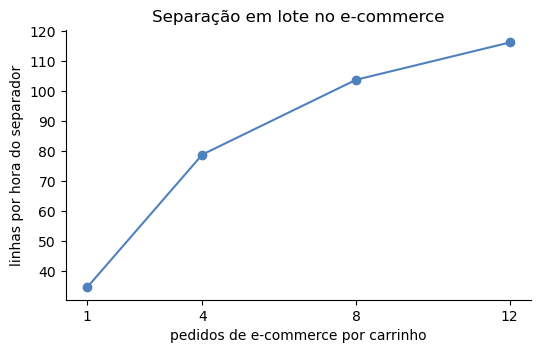

In [4]:
# Linha com marcadores: mostra o retorno decrescente ao aumentar o tamanho do lote.
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(batch.pedidos_por_carrinho, batch.linhas_por_hora, marker="o", color="#4F81BD")
ax.set_xlabel("pedidos de e-commerce por carrinho"); ax.set_ylabel("linhas por hora do separador")
ax.set_title("Separação em lote no e-commerce"); ax.set_xticks(batch.pedidos_por_carrinho)
savefig(fig, "07a_batch_ecommerce", out=PH7)

**Leitura:** agrupar pedidos multiplica a produtividade do e-commerce, com **retorno decrescente**:
o maior salto é de 1 para 4 pedidos; acima de 8 o ganho de viagem é comido pela triagem e o carrinho
fica grande. Recomendação: **carrinho de 8 volumes** (multi-tote) para o e-commerce, com conferência
por leitura do código de barras na triagem (evita trocar itens entre pedidos).

## 3. Roteirização na planta em escala cheia
Na escala 10% cada zona tem só 1–2 ruas de picking, e a regra de percurso quase não muda nada. Para
avaliar a roteirização usamos a **geometria da planta real** (`config/layout.yaml`: 18 ruas no seco,
prédios de 2,7 m, corredor transversal na frente) e listas de separação **sorteadas a partir do perfil
real**: número de linhas de um sub-pedido B2B do seco e popularidade das faces copiada da curva de
visitas real (Fase 5).

Regras de percurso comparadas:
- **Retorno:** entra em cada rua com item até o mais fundo e volta pela mesma frente.
- **S-shape (serpentina):** atravessa inteira cada rua com item, alternando o sentido.
- **Melhor das duas:** para cada lista, a menor (o que um WMS com roteirização faria).

E duas formas de distribuir os SKUs nas faces: **aleatória** (como hoje, ordem de cadastro) e
**por popularidade** (mais visitados nas faces mais perto da expedição).

In [5]:
with open(ROOT / "config" / "layout.yaml", encoding="utf-8") as f:
    L = yaml.safe_load(f)
R, B = L["rack"], L["rack_blocks"]["dry"]
passo = 2 * R["rack_depth_m"] + R["flue_m"] + R["aisle_width_m"]          # distância entre ruas
x_rua = B["origin"][0] + R["rack_depth_m"] + R["aisle_width_m"] / 2 + passo * np.arange(B["aisles"])
prof_rua = B["sections"] * B["bays_per_section"] * R["bay_width_m"] + B["cross_aisle_m"]
y0 = B["origin"][1]
# Faces: 2 lados x prédios x seções por rua (nível 1); y = meio do prédio
faces = pd.DataFrame([(a, y0 + (b + 0.5) * R["bay_width_m"] + (B["cross_aisle_m"] if b >= B["bays_per_section"] else 0))
                      for a in range(B["aisles"]) for b in range(B["sections"] * B["bays_per_section"])
                      for _ in range(2 * R["slots_per_level"])], columns=["rua", "y"])
faces["x"] = x_rua[faces.rua]
ox, oy = P["productivity"]["travel_origin"]["dry"]
faces["dist"] = (faces.x - ox).abs() + (faces.y - oy).abs()
print(f"Planta seco: {B['aisles']} ruas, {len(faces):,} faces, profundidade da rua {prof_rua:.1f} m")

# Popularidade: curva real de visitas dos SKUs secos (Fase 5), reamostrada para o nº de faces
rng = np.random.default_rng(P["flow_simulation"]["seed"])
vis = slot[(slot.zone == "dry") & (slot.visitas_ano > 0)].visitas_ano.values
pop = np.sort(rng.choice(vis, len(faces)))[::-1]
pop = pop / pop.sum()
ordem_perto = faces.dist.argsort().values
aleatorio = rng.permutation(len(faces))
faces["pop_por_popularidade"] = 0.0; faces.loc[ordem_perto, "pop_por_popularidade"] = pop
faces["pop_aleatorio"] = 0.0;       faces.loc[aleatorio, "pop_aleatorio"] = pop

# Tamanho da lista: linhas de sub-pedidos B2B do seco no mês de referência
n_linhas = sub[(sub.channel == "B2B") & (sub.zone == "dry")].n_lines.values

def distancia_rota(idx, regra):
    """Distância (m) de uma rota que visita as faces `idx`, saindo e voltando à expedição."""
    f = faces.iloc[idx]
    ruas = np.sort(f.rua.unique())
    xs = x_rua[ruas]
    # deslocamento pelo corredor da frente (da expedição até as ruas extremas e de volta)
    frente = 2 * (max(xs.max(), ox) - min(xs.min(), ox)) + 2 * (y0 - oy)
    fundo = f.groupby("rua").y.max().reindex(ruas).values - y0       # até o item mais fundo de cada rua
    retorno = frente + 2 * fundo.sum()
    n = len(ruas)
    s_shape = frente + n * prof_rua + (0 if n % 2 == 0 else 0)        # n ímpar: a última rua sai pelo fundo
    if n % 2 == 1:                                                    # ... e volta pelo fundo até a frente
        s_shape += prof_rua
    return {"retorno": retorno, "s_shape": s_shape}[regra] if regra != "melhor" else min(retorno, s_shape)

amostra = []
for i in range(ST["routing_sample_orders"]):
    n = int(rng.choice(n_linhas))
    for nome_slot in ["aleatorio", "por_popularidade"]:
        idx = rng.choice(len(faces), size=n, replace=True, p=faces[f"pop_{nome_slot}"].values)
        for regra in ["retorno", "s_shape", "melhor"]:
            amostra.append((i, n, nome_slot, regra, distancia_rota(idx, regra)))
rotas = pd.DataFrame(amostra, columns=["lista", "linhas", "slotting", "regra", "dist_m"])
tab_rotas = rotas.pivot_table(index="slotting", columns="regra", values="dist_m", aggfunc="mean")
tab_rotas = tab_rotas[["retorno", "s_shape", "melhor"]]
base_rota = tab_rotas.loc["aleatorio", "retorno"]
save(tab_rotas.reset_index().round(1), "07a_roteirizacao", out=PH7)
print(f"Distância média da rota (m), {ST['routing_sample_orders']} listas sorteadas:")
tab_rotas.round(0)

Planta seco: 18 ruas, 2,304 faces, profundidade da rua 90.4 m


Distância média da rota (m), 2000 listas sorteadas:


regra,retorno,s_shape,melhor
slotting,,,
aleatorio,1451.0,1317.0,1290.0
por_popularidade,827.0,1162.0,826.0


Redução vs. (aleatório + retorno):


regra,retorno,s_shape,melhor
slotting,,,
aleatorio,0.0,9.3,11.1
por_popularidade,43.0,19.9,43.1


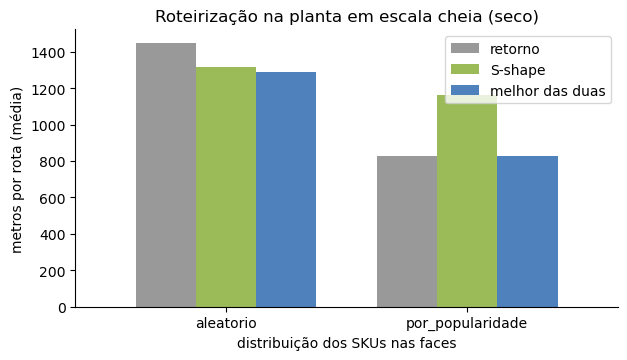

In [6]:
# Barras agrupadas: 2 slottings x 3 regras (poucas categorias, comparação direta).
fig, ax = plt.subplots(figsize=(7, 3.6))
(tab_rotas / 1).plot.bar(ax=ax, rot=0, color=["#999999", "#9BBB59", "#4F81BD"], width=0.75)
ax.set_ylabel("metros por rota (média)"); ax.set_xlabel("distribuição dos SKUs nas faces")
ax.set_title("Roteirização na planta em escala cheia (seco)"); ax.legend(["retorno", "S-shape", "melhor das duas"])
savefig(fig, "07a_roteirizacao", out=PH7)
print("Redução vs. (aleatório + retorno):")
(100 * (1 - tab_rotas / base_rota)).round(1)

**Leitura:**
- Com o slotting **aleatório** de hoje, os itens estão espalhados pelo bloco: a **S-shape** anda ~9%
  menos que o retorno, e escolher a melhor regra por lista dá ~11%.
- Com slotting **por popularidade**, a rota cai **~43%**. Nesse caso a melhor regra passa a ser o
  **retorno**: os itens ficam na frente das ruas, e atravessar a rua inteira (S-shape) desperdiça caminho.
- Ou seja, **a regra de percurso certa depende do slotting**. O WMS deve escolher a rota lista a lista,
  e o slotting vem primeiro: ele é a mudança física que gera o ganho grande. A roteirização é configuração.

In [7]:
# Ganho de horas: andar menos no B2B do seco (escala cheia = x10), usando o melhor resultado das rotas
reducao_rota = 1 - tab_rotas.loc["por_popularidade", "melhor"] / base_rota
viagem_b2b_seco_h = prod.loc[("B2B", "dry"), "viagem_h"] * 12 * prm["scale"]     # horas/ano de caminhada
horas_rota = viagem_b2b_seco_h * reducao_rota
batch8 = batch.set_index("pedidos_por_carrinho").loc[8]
horas_batch = (batch.horas_mes_escala10.iloc[0] - batch8.horas_mes_escala10) * 12 * prm["scale"]
c_h = P["labor_cost"]["picker_brl_h"]
print(f"Batch 8 no e-commerce: −{horas_batch:,.0f} h/ano de separação ≈ R$ {horas_batch * c_h:,.0f}/ano (escala cheia)")
print(f"Slotting + roteirização no B2B seco: −{horas_rota:,.0f} h/ano de caminhada ≈ R$ {horas_rota * c_h:,.0f}/ano "
      f"(parte desse ganho já está contada no slotting da Fase 5)")
register_saving(7, "Separação em lote do e-commerce (carrinho de 8 pedidos)", "horas de separação e-commerce/ano",
                round(batch.horas_mes_escala10.iloc[0] * 12 * prm["scale"]),
                round(batch8.horas_mes_escala10 * 12 * prm["scale"]),
                f"linhas/h e-commerce {batch.linhas_por_hora.iloc[0]:.0f} -> {batch8.linhas_por_hora:.0f}",
                "picker_brl_h do config; escala cheia; out/2025 x 12", horas_batch * c_h,
                "carrinhos multi-volume + leitor (a orçar)")
register_saving(7, "Roteirização S-shape/melhor rota no WMS (B2B seco)", "horas de caminhada B2B seco/ano",
                round(viagem_b2b_seco_h), round(viagem_b2b_seco_h * (1 - (1 - tab_rotas.loc['aleatorio', 'melhor'] / base_rota))),
                "só a regra de percurso, slotting atual", "picker_brl_h; escala cheia; experimento na planta cheia",
                viagem_b2b_seco_h * (1 - tab_rotas.loc["aleatorio", "melhor"] / base_rota) * c_h, "configuração do WMS")
log(NB, f"produtividade por canal/zona (out/2025); batch e-commerce k={ST['batch_sizes']} em pedidos reais; "
        f"roteirização em {ST['routing_sample_orders']} listas sorteadas na planta cheia (retorno, S-shape)")

Batch 8 no e-commerce: −33,250 h/ano de separação ≈ R$ 930,996/ano (escala cheia)
Slotting + roteirização no B2B seco: −6,940 h/ano de caminhada ≈ R$ 194,322/ano (parte desse ganho já está contada no slotting da Fase 5)
